In [1]:
from pathlib import Path
from collections import Counter
import random

import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = Path(r"C:\Programming\Projects\Traffic\dataset\traffic_sign")
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Dataset folder exists:", DATASET_DIR.exists())
print("Train folder exists:", TRAIN_DIR.exists())
print("Test folder exists:", TEST_DIR.exists())

if not TRAIN_DIR.exists() or not TEST_DIR.exists():
    raise FileNotFoundError(
        "Could not find train/test folders. Check DATASET_DIR and make sure "
        "it contains the train and test folders."
    )


Dataset folder exists: True
Train folder exists: True
Test folder exists: True


In [2]:
def count_images_by_class(split_dir):
    counts = {}
    for folder in split_dir.iterdir():
        if folder.is_dir():
            counts[folder.name] = sum(
                1 for file in folder.rglob("*")
                if file.is_file() and file.suffix.lower() in IMAGE_EXTS
            )
    return counts

train_counts = count_images_by_class(TRAIN_DIR)
test_counts = count_images_by_class(TEST_DIR)

for split_name, counts in [("TRAIN", train_counts), ("TEST", test_counts)]:
    print(f"\n{split_name} DATASET")
    print("Number of classes:", len(counts))
    print("Total images:", sum(counts.values()))
    print("First 10 classes:", sorted(counts)[:10])



TRAIN DATASET
Number of classes: 85
Total images: 4438
First 10 classes: ['ALL_MOTOR_VEHICLE_PROHIBITED', 'AXLE_LOAD_LIMIT', 'BARRIER_AHEAD', 'BULLOCK_AND_HANDCART_PROHIBITED', 'BULLOCK_PROHIBITED', 'CATTLE', 'COMPULSARY_AHEAD', 'COMPULSARY_AHEAD_OR_TURN_LEFT', 'COMPULSARY_AHEAD_OR_TURN_RIGHT', 'COMPULSARY_CYCLE_TRACK']

TEST DATASET
Number of classes: 85
Total images: 1288
First 10 classes: ['ALL_MOTOR_VEHICLE_PROHIBITED', 'AXLE_LOAD_LIMIT', 'BARRIER_AHEAD', 'BULLOCK_AND_HANDCART_PROHIBITED', 'BULLOCK_PROHIBITED', 'CATTLE', 'COMPULSARY_AHEAD', 'COMPULSARY_AHEAD_OR_TURN_LEFT', 'COMPULSARY_AHEAD_OR_TURN_RIGHT', 'COMPULSARY_CYCLE_TRACK']


In [3]:
train_values = list(train_counts.values())

print("Classes:", len(train_counts))
print("Minimum images in a class:", min(train_values) if train_values else 0)
print("Maximum images in a class:", max(train_values) if train_values else 0)
print(
    "Average images per class:",
    round(sum(train_values) / len(train_values), 2) if train_values else 0
)

print("\n5 classes with fewest images:")
print(sorted(train_counts.items(), key=lambda item: item[1])[:5])

print("\n5 classes with most images:")
print(sorted(train_counts.items(), key=lambda item: item[1], reverse=True)[:5])


Classes: 85
Minimum images in a class: 2
Maximum images in a class: 242
Average images per class: 52.21

5 classes with fewest images:
[('FERRY', 2), ('UNGUARDED_LEVEL_CROSSING', 5), ('COMPULSARY_TURN_RIGHT', 6), ('DIRECTION', 6), ('RESTRICTION_ENDS', 6)]

5 classes with most images:
[('NO_STOPPING_OR_STANDING', 242), ('SPEED_LIMIT_30', 238), ('COMPULSARY_KEEP_RIGHT', 223), ('SPEED_LIMIT_50', 200), ('SPEED_LIMIT_80', 192)]


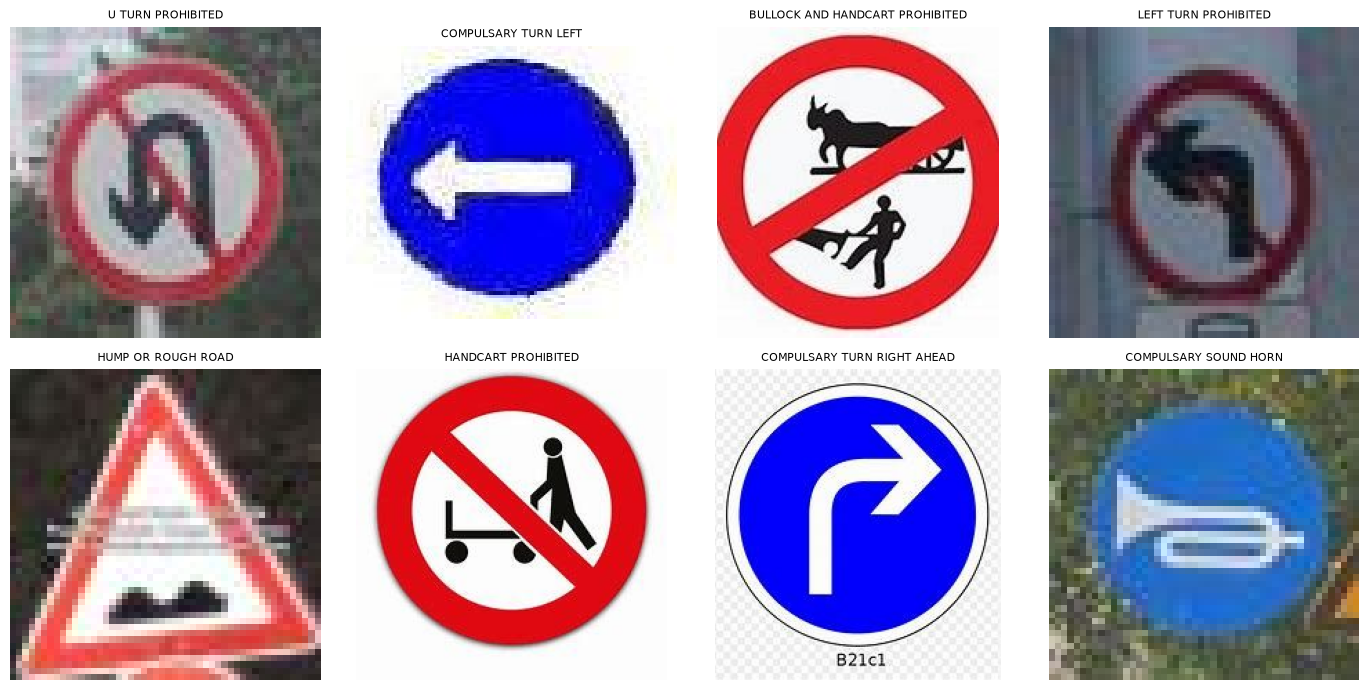

In [4]:
random.seed(42)

class_folders = sorted(
    folder for folder in TRAIN_DIR.iterdir()
    if folder.is_dir() and train_counts.get(folder.name, 0) > 0
)
selected_folders = random.sample(class_folders, min(8, len(class_folders)))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    ax.axis("off")

for ax, folder in zip(axes.flat, selected_folders):
    image_files = [
        file for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTS
    ]
    if image_files:
        image_path = random.choice(image_files)
        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(folder.name.replace("_", " "), fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()


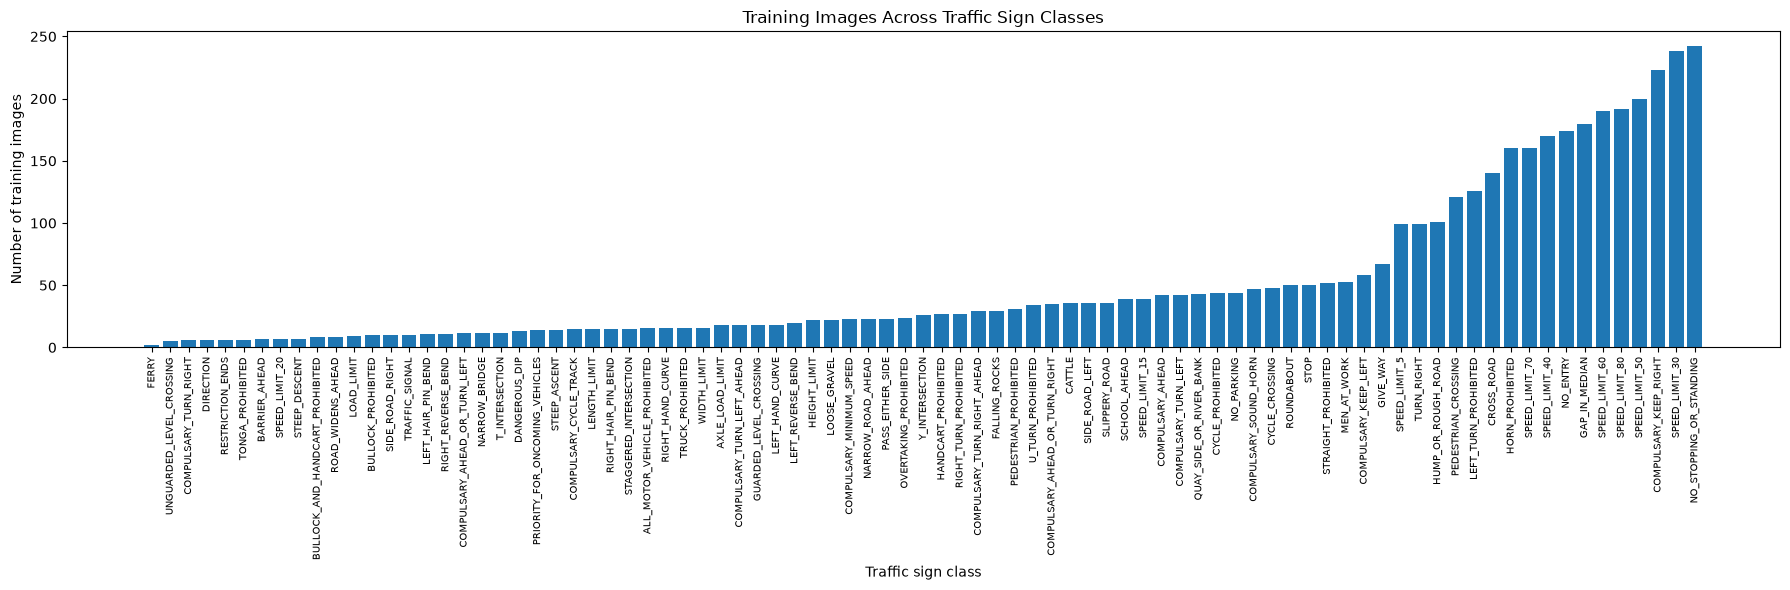

In [5]:
sorted_counts = sorted(train_counts.items(), key=lambda item: item[1])

plt.figure(figsize=(18, 6))
plt.bar(
    [name for name, count in sorted_counts],
    [count for name, count in sorted_counts]
)
plt.xticks(rotation=90, fontsize=7)
plt.xlabel("Traffic sign class")
plt.ylabel("Number of training images")
plt.title("Training Images Across Traffic Sign Classes")
plt.tight_layout()
plt.show()


In [6]:
size_counts = Counter()
corrupted_files = []
images_checked = 0

for file in TRAIN_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in IMAGE_EXTS:
        images_checked += 1
        try:
            with Image.open(file) as img:
                size_counts[img.size] += 1
                img.verify()
        except Exception:
            corrupted_files.append(str(file))

print("Images checked:", images_checked)
print("Corrupted images:", len(corrupted_files))
print("Most common image sizes:", size_counts.most_common(10))

if corrupted_files:
    print("\nFirst 5 corrupted files:")
    for file in corrupted_files[:5]:
        print(file)


Images checked: 4438
Corrupted images: 0
Most common image sizes: [((50, 50), 2891), ((3456, 4608), 485), ((150, 150), 26), ((225, 225), 25), ((143, 225), 24), ((208, 225), 17), ((210, 225), 17), ((215, 225), 14), ((213, 225), 14), ((257, 257), 14)]


In [7]:
train_classes = set(train_counts)
test_classes = set(test_counts)

print("Train classes:", len(train_classes))
print("Test classes:", len(test_classes))
print("Classes only in train:", sorted(train_classes - test_classes))
print("Classes only in test:", sorted(test_classes - train_classes))
print("Matching class names:", train_classes == test_classes)

print("\nTest images:", sum(test_counts.values()))
print("5 classes with fewest test images:")
print(sorted(test_counts.items(), key=lambda item: item[1])[:5])


Train classes: 85
Test classes: 85
Classes only in train: []
Classes only in test: []
Matching class names: True

Test images: 1288
5 classes with fewest test images:
[('DIRECTION', 1), ('FERRY', 1), ('UNGUARDED_LEVEL_CROSSING', 1), ('BARRIER_AHEAD', 2), ('BULLOCK_AND_HANDCART_PROHIBITED', 2)]


In [8]:
import json

CLASS_NAMES = sorted(train_classes)
class_to_idx = {name: index for index, name in enumerate(CLASS_NAMES)}

print("Number of classes:", len(CLASS_NAMES))
print("First 10 mappings:")
for name in CLASS_NAMES[:10]:
    print(f"{name}: {class_to_idx[name]}")

metadata = {
    "class_names": CLASS_NAMES,
    "class_to_idx": class_to_idx,
    "num_classes": len(CLASS_NAMES),
    "train_images": sum(train_counts.values()),
    "test_images": sum(test_counts.values())
}

metadata_path = DATASET_DIR / "class_mapping.json"
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False)

print("\nMetadata saved to:", metadata_path)


Number of classes: 85
First 10 mappings:
ALL_MOTOR_VEHICLE_PROHIBITED: 0
AXLE_LOAD_LIMIT: 1
BARRIER_AHEAD: 2
BULLOCK_AND_HANDCART_PROHIBITED: 3
BULLOCK_PROHIBITED: 4
CATTLE: 5
COMPULSARY_AHEAD: 6
COMPULSARY_AHEAD_OR_TURN_LEFT: 7
COMPULSARY_AHEAD_OR_TURN_RIGHT: 8
COMPULSARY_CYCLE_TRACK: 9

Metadata saved to: C:\Programming\Projects\Traffic\dataset\traffic_sign\class_mapping.json


In [9]:
print("Dataset inspection complete.")
print("Train classes:", len(train_counts))
print("Train images:", sum(train_counts.values()))
print("Test classes:", len(test_counts))
print("Test images:", sum(test_counts.values()))
print("Train/test class names match:", set(train_counts) == set(test_counts))


Dataset inspection complete.
Train classes: 85
Train images: 4438
Test classes: 85
Test images: 1288
Train/test class names match: True
